# Cleaning a real dataset with `dstoolkit`

Each step from `dstoolkit` applied to the Titanic passenger list (1,309 rows): duplicates, missing values, outliers, encoding and scaling. Every function returns a new DataFrame, so the raw data stays available for comparison.

In [1]:
import pandas as pd
import dstoolkit as dst

raw = pd.read_csv('../data/titanic3.csv', na_values='?')
raw.isna().sum()[lambda s: s > 0]

age           263
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

## 1. Duplicates

In [2]:
df = dst.remove_duplicates(raw)

No duplicates found.


## 2. Missing values

`cabin`, `boat` and `body` are mostly empty: filling them would invent data, so only `age`, `fare` and `embarked` are filled. Age uses the median, which a few very old passengers can't drag upward the way they would the mean.

In [3]:
df = dst.fill_missing(df, numeric='median', columns=['age', 'fare', 'embarked'])

Filled missing values: age (263), fare (1), embarked (2)


In [4]:
print(f"Median age used for {raw.age.isna().sum()} passengers: {raw.age.median()}")

Median age used for 263 passengers: 28.0


## 3. Outliers in fare

A few first-class tickets cost over £500. `find_outliers` shows how many fares fall outside 1.5 × the interquartile range:

In [5]:
flags = dst.find_outliers(df, ['fare'])
print(f"{flags.fare.sum()} of {len(df)} fares are outliers")

171 of 1309 fares are outliers


Removing 13% of passengers would throw away most of first class, so instead fares are **capped** at the upper bound (rows are kept), and a log-scaled copy is added for charts and models that prefer a less skewed column.

In [6]:
df = dst.handle_outliers(df, ['fare'], action='cap')
df = dst.log_transform(df, ['fare'], suffix='_log')

Capped outliers: fare (171)
Log-transformed ['fare'].


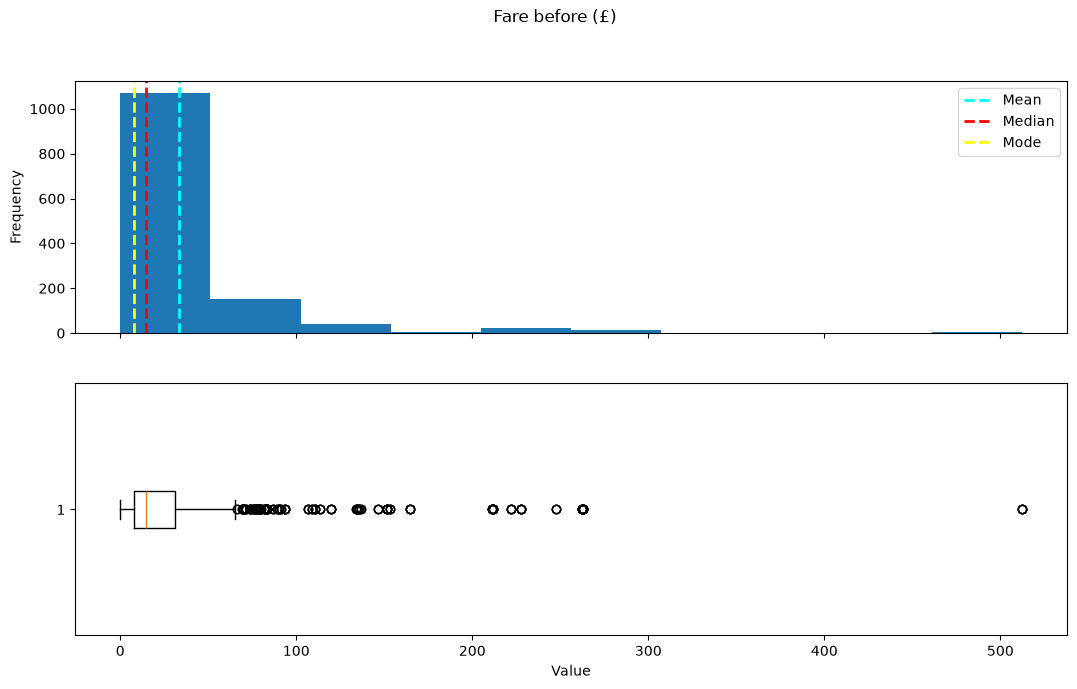

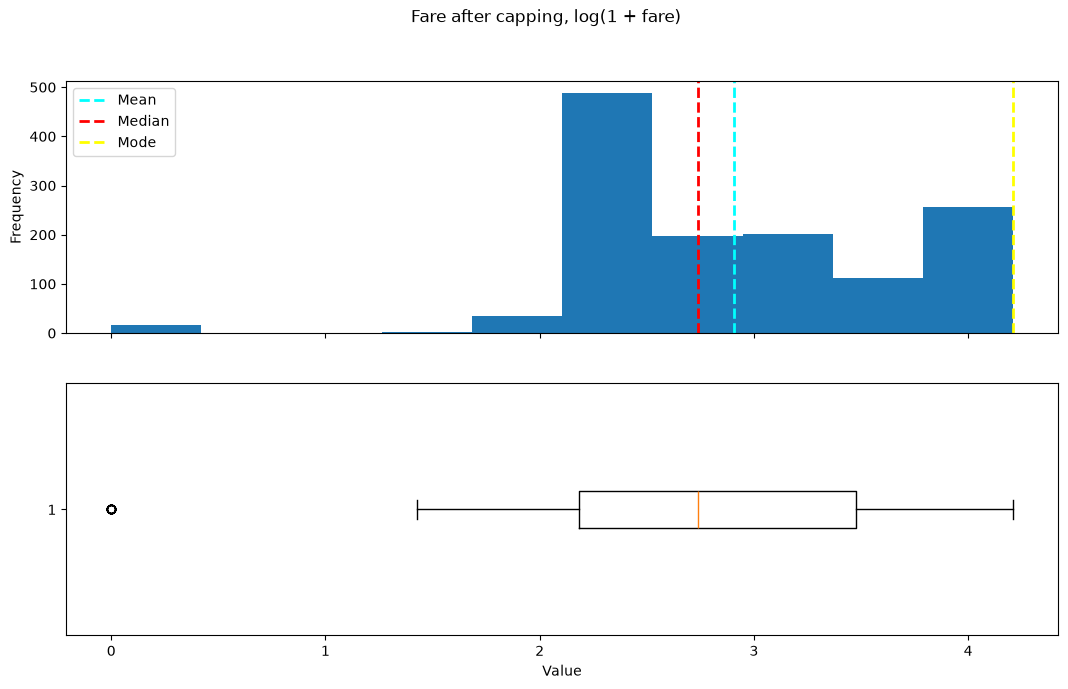

In [7]:
dst.show_distribution(raw.fare, title='Fare before (£)')
dst.show_distribution(df.fare_log, title='Fare after capping, log(1 + fare)');

## 4. Encoding categories

`sex` becomes a 0/1 code; port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton) becomes one column per port.

In [8]:
df = dst.encode_categorical(df, {'sex': 'label', 'embarked': 'onehot'})
df[['sex', 'sex_label', 'embarked', 'embarked_C', 'embarked_Q', 'embarked_S']].head()

sex labels: female=0, male=1
Encoded sex (label), embarked (onehot).


,sex,sex_label,embarked,embarked_C,embarked_Q,embarked_S
0,female,0,S,0,0,1
1,male,1,S,0,0,1
2,female,0,S,0,0,1
3,male,1,S,0,0,1
4,female,0,S,0,0,1


## 5. Scaling

Age rescaled to 0–1 and the log fare standardized, ready for a distance-based model such as k-nearest neighbours.

In [9]:
df = dst.normalize(df, {'age': 'minmax', 'fare_log': 'zscore'})
df[['age', 'fare_log']].describe().round(2)

Normalized age (minmax), fare_log (zscore).


,age,fare_log
count,1309.00,1309.00
mean,0.37,0.00
std,0.16,1.00
min,0.00,-3.53
25%,0.27,-0.88
50%,0.35,-0.20
75%,0.44,0.69
max,1.00,1.59


## All in one call

`clean()` runs the same steps in order. (The log transform is a separate step, so this version scales the capped fare directly.)

In [10]:
cleaned = dst.clean(
    raw,
    missing={'numeric': 'median', 'columns': ['age', 'fare', 'embarked']},
    outliers={'columns': ['fare'], 'action': 'cap'},
    encode={'columns': {'sex': 'label', 'embarked': 'onehot'}},
    scale={'columns': {'age': 'minmax', 'fare': 'zscore'}},
)
cleaned.shape

No duplicates found.
Filled missing values: age (263), fare (1), embarked (2)
Capped outliers: fare (171)
sex labels: female=0, male=1
Encoded sex (label), embarked (onehot).
Normalized age (minmax), fare (zscore).


(1309, 18)

## Age from a date of birth

The Titanic list records age directly, so `add_age_column` is shown on a small example. It finds the birth-date column by name and counts completed years, here at a fixed date so the result doesn't change over time:

In [11]:
patients = pd.DataFrame({'patient': ['A', 'B', 'C'],
                         'date_of_birth': ['1950-03-14', '1962-11-30', '1948-07-01'],
                         'admitted': ['2020-03-13', '2020-12-01', '2020-07-01']})
dst.add_age_column(patients, as_of='admitted', name='age_at_admission')

Added 'age_at_admission' from 'date_of_birth'.


,patient,date_of_birth,age_at_admission,admitted
0,A,1950-03-14,69,2020-03-13
1,B,1962-11-30,58,2020-12-01
2,C,1948-07-01,72,2020-07-01
